# Лабораторная работа № 1
## Аудит Anaconda Jupyter Notebook

In [1]:
import platform
import sys
import psutil

print("Python:", platform.python_version())
print("Платформа:", platform.platform())
print("Окружение:", sys.prefix)
print("Логические ядра:", psutil.cpu_count())
print(f"ОЗУ: {psutil.virtual_memory().total / 2**30:.1f} ГиБ")

Python: 3.11.16
Платформа: macOS-15.0-arm64-arm-64bit
Окружение: /opt/anaconda3/envs/lab1_terminal
Логические ядра: 8
ОЗУ: 16.0 ГиБ


In [2]:
from importlib.metadata import PackageNotFoundError, version

for name in ("numpy", "pandas", "matplotlib", "seaborn", "scikit-learn"):
    try:
        print(f"{name:<15} {version(name)}")
    except PackageNotFoundError:
        print(f"{name:<15} отсутствует")

numpy           2.4.6
pandas          3.0.5
matplotlib      3.11.0
seaborn         0.13.2
scikit-learn    1.9.0


## Iris
Сравним длину и ширину лепестков у трёх видов ириса.

In [3]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.datasets import load_iris, load_wine

sns.set_theme(style="whitegrid")
iris = load_iris(as_frame=True)
iris_df = pd.DataFrame(iris.frame)
iris_df["Вид"] = iris_df["target"].map(dict(enumerate(iris.target_names)))
print("Размер таблицы признаков:", iris.data.shape)
print("Пропусков:", iris_df.isna().sum().sum())
display(iris_df.drop(columns="target").head())

Размер таблицы признаков: (150, 4)
Пропусков: 0


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),Вид
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


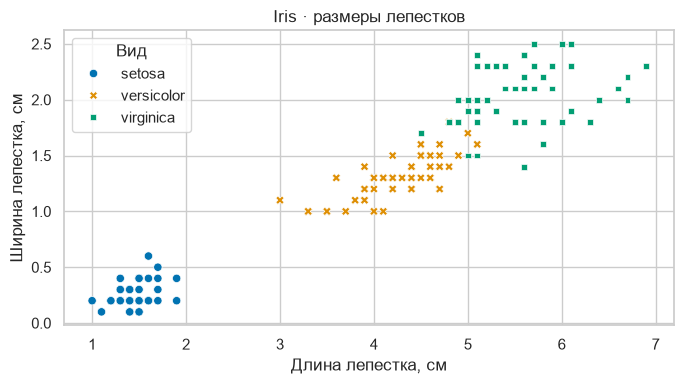

In [4]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.scatterplot(data=iris_df, x="petal length (cm)", y="petal width (cm)",
                hue="Вид", style="Вид", palette="colorblind", ax=ax)
ax.set(title="Iris · размеры лепестков",
       xlabel="Длина лепестка, см", ylabel="Ширина лепестка, см")
fig.tight_layout()
plt.show()

Лепестки setosa заметно короче и уже. Области versicolor и virginica частично перекрываются.

## Wine
Сравним содержание алкоголя в образцах вина трёх классов.

In [5]:
wine = load_wine(as_frame=True)
wine_df = pd.DataFrame(wine.frame)
wine_df["Класс"] = wine_df["target"].map({0: "Класс 0", 1: "Класс 1", 2: "Класс 2"})
print("Размер таблицы признаков:", wine.data.shape)
print("Пропусков:", wine_df.isna().sum().sum())
display(wine_df[["Класс", "alcohol", "malic_acid", "ash"]].head())
display(wine_df.groupby("Класс")["alcohol"].median().rename("Медиана").round(2))

Размер таблицы признаков: (178, 13)
Пропусков: 0


,Класс,alcohol,malic_acid,ash
0,Класс 0,14.23,1.71,2.43
1,Класс 0,13.20,1.78,2.14
2,Класс 0,13.16,2.36,2.67
3,Класс 0,14.37,1.95,2.50
4,Класс 0,13.24,2.59,2.87


Класс
Класс 0    13.75
Класс 1    12.29
Класс 2    13.16
Name: Медиана, dtype: float64

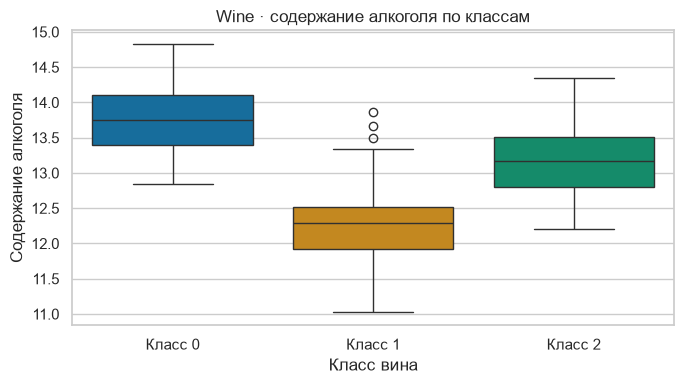

In [6]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.boxplot(data=wine_df, x="Класс", y="alcohol", hue="Класс",
            palette="colorblind", legend=False, ax=ax)
ax.set(title="Wine · содержание алкоголя по классам",
       xlabel="Класс вина", ylabel="Содержание алкоголя")
fig.tight_layout()
plt.show()

Медиана выше всего у класса 0 и ниже всего у класса 1. На диаграмме медиана показана линией внутри прямоугольника.